In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:
import zipfile
import os

zip_path = "/content/groundwater.zip"
extract_path = "/content/groundwater_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

ZIP file extracted successfully!
/content/groundwater_data/sector_contribution_summary.csv
/content/groundwater_data/state_wise_stress_summary.csv
/content/groundwater_data/cleaned_groundwater_dataset.csv
/content/groundwater_data/top_10_districts.csv
/content/groundwater_data/stress_category_summary.csv


In [6]:
file_path = "/content/groundwater_data/cleaned_groundwater_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (706, 21)


,State,Serial_No,District,Monsoon_Rainfall_Recharge,Monsoon_Other_Recharge,NonMonsoon_Rainfall_Recharge,NonMonsoon_Other_Recharge,Total_Annual_Recharge,Natural_Discharge,Extractable_Resource,...,Industrial_Extraction,Domestic_Extraction,Total_Annual_Extraction,Domestic_Allocation_2030,Future_Availability,Extraction_Stage_Percent,Stress_Category,Irrigation_Share_Percent,Industrial_Share_Percent,Domestic_Share_Percent
0,Andhra Pradesh,1,Alluri Sitharama Raju,44343.14,4295.79,1850.65,2266.03,52755.61,2638.05,50117.56,...,0.00,1579.66,2146.48,2173.35,47784.38,4.28,Safe,26.391581,0.000000,73.593045
1,Andhra Pradesh,2,Anakapalli,20898.07,32462.58,14295.05,5241.75,72897.45,3645.22,69252.24,...,489.46,4957.88,21723.97,8163.16,45060.58,31.37,Safe,74.924335,2.253087,22.822164
2,Andhra Pradesh,3,Ananthapuramu,41668.06,44121.60,641.38,39688.98,126120.02,6306.09,119813.93,...,727.29,3466.80,41819.10,3466.80,78907.83,34.90,Safe,89.970540,1.739134,8.289992
3,Andhra Pradesh,4,Annamayya,44650.83,18221.52,2879.64,23640.84,89392.83,4469.87,84922.96,...,137.75,3825.77,33249.92,4539.70,51486.28,39.15,Safe,88.079490,0.414287,11.506103
4,Andhra Pradesh,5,Bapatla,20572.41,37391.34,2035.21,12659.44,72658.40,3632.97,69025.43,...,63.94,2182.63,17758.14,2590.29,51238.99,25.73,Safe,87.349520,0.360060,12.290871


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['State', 'Serial_No', 'District', 'Monsoon_Rainfall_Recharge', 'Monsoon_Other_Recharge', 'NonMonsoon_Rainfall_Recharge', 'NonMonsoon_Other_Recharge', 'Total_Annual_Recharge', 'Natural_Discharge', 'Extractable_Resource', 'Irrigation_Extraction', 'Industrial_Extraction', 'Domestic_Extraction', 'Total_Annual_Extraction', 'Domestic_Allocation_2030', 'Future_Availability', 'Extraction_Stage_Percent', 'Stress_Category', 'Irrigation_Share_Percent', 'Industrial_Share_Percent', 'Domestic_Share_Percent']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 706 entries, 0 to 705
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   State                         706 non-null    object 
 1   Serial_No                     706 non-null    int64  
 2   District                      706 non-null    object 
 3   Monsoon_Rainfall_Recharge     706 non-null    float64
 4  

DATASET LOADED

checks the dataset for missing values, duplicate district records,
and consistency in groundwater extraction calculations

In [8]:
# DATA VALIDATION

print("=" * 50)
print("DATA VALIDATION")
print("=" * 50)

# 1. Dataset dimensions
print("\nTotal records:", len(df))
print("Total columns:", len(df.columns))

# 2. Missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# 3. Duplicate district records
duplicates = df.duplicated(subset=["State", "District"]).sum()
print("\nDuplicate state-district records:", duplicates)

# 4. Unique states and districts
print("\nUnique states/UTs:", df["State"].nunique())
print("Unique districts:", df["District"].nunique())

# 5. Verify extraction stage calculation
calculated_stage = (
    df["Total_Annual_Extraction"] /
    df["Extractable_Resource"]
) * 100

difference = (
    df["Extraction_Stage_Percent"] - calculated_stage
).abs()

print("\nMaximum extraction-stage difference:",
      difference.max())

# 6. Check stress categories
print("\nStress category distribution:")
print(df["Stress_Category"].value_counts())

print("\nValidation completed!")

DATA VALIDATION

Total records: 706
Total columns: 21

Missing values:
0

Duplicate state-district records: 0

Unique states/UTs: 36
Unique districts: 703

Maximum extraction-stage difference: 0.004995775272263359

Stress category distribution:
Stress_Category
Safe              517
Over-Exploited     94
Semi-Critical      74
Critical           21
Name: count, dtype: int64

Validation completed!


Exploratory Data Analysis

In [9]:
# BASIC STATISTICAL ANALYSIS

print("=" * 55)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 55)

# Statistical summary of numerical columns
print("\n1. Statistical Summary")
display(df.describe().round(2))

# National extraction-stage statistics
print("\n2. Groundwater Extraction Stage")

print("Mean:",
      round(df["Extraction_Stage_Percent"].mean(), 2), "%")

print("Median:",
      round(df["Extraction_Stage_Percent"].median(), 2), "%")

print("Minimum:",
      round(df["Extraction_Stage_Percent"].min(), 2), "%")

print("Maximum:",
      round(df["Extraction_Stage_Percent"].max(), 2), "%")

print("Standard Deviation:",
      round(df["Extraction_Stage_Percent"].std(), 2))

EXPLORATORY DATA ANALYSIS

1. Statistical Summary


,Serial_No,Monsoon_Rainfall_Recharge,Monsoon_Other_Recharge,NonMonsoon_Rainfall_Recharge,NonMonsoon_Other_Recharge,Total_Annual_Recharge,Natural_Discharge,Extractable_Resource,Irrigation_Extraction,Industrial_Extraction,Domestic_Extraction,Total_Annual_Extraction,Domestic_Allocation_2030,Future_Availability,Extraction_Stage_Percent,Irrigation_Share_Percent,Industrial_Share_Percent,Domestic_Share_Percent
count,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00,706.00
mean,17.39,34752.99,12350.39,3373.04,13051.05,63530.09,5780.47,57755.47,30467.14,598.72,3950.48,35016.35,5158.56,26414.39,59.30,72.48,2.60,24.92
std,14.47,28456.61,15128.10,6312.28,13893.40,46436.96,5955.35,42492.94,32561.70,1406.25,4000.18,34815.09,9301.09,25787.02,46.99,28.08,6.03,27.02
min,1.00,57.52,0.00,0.00,0.00,186.82,9.34,177.48,0.00,0.00,0.00,6.56,0.00,0.00,0.14,0.00,0.00,0.00
25%,6.00,14477.76,1517.78,215.46,2478.52,27998.22,2334.37,25310.13,5434.42,16.26,1286.44,9462.14,1746.97,6548.11,30.59,65.78,0.11,7.20
50%,14.00,27841.87,5871.91,1279.92,9001.70,54261.46,4615.82,49177.26,23733.00,107.80,2621.54,27773.40,3265.73,19470.64,51.78,84.26,0.65,13.66
75%,24.00,48975.37,17301.80,3298.16,18472.06,90772.07,7378.87,82207.93,43967.38,609.88,5153.28,48852.50,6352.83,37574.12,71.81,91.86,2.36,29.12
max,75.00,157982.51,93489.20,42220.16,86270.38,240759.01,70984.28,218332.66,223357.63,17142.51,42974.34,242359.13,202365.14,137357.20,321.84,99.73,59.92,100.11



2. Groundwater Extraction Stage
Mean: 59.3 %
Median: 51.77 %
Minimum: 0.14 %
Maximum: 321.84 %
Standard Deviation: 46.99


In [10]:
# TOP 10 DISTRICTS WITH HIGHEST EXTRACTION STAGE

top_10 = df.nlargest(10, "Extraction_Stage_Percent")[
    ["State", "District", "Extractable_Resource",
     "Total_Annual_Extraction", "Extraction_Stage_Percent"]
]

print("TOP 10 DISTRICTS WITH HIGHEST GROUNDWATER EXTRACTION")
display(top_10.round(2))

TOP 10 DISTRICTS WITH HIGHEST GROUNDWATER EXTRACTION


,State,District,Extractable_Resource,Total_Annual_Extraction,Extraction_Stage_Percent
462,Rajasthan,Jaisalmer,9614.27,30942.89,321.84
443,Punjab,Sangrur,63227.66,195997.90,309.99
434,Punjab,Malerkotla,19433.77,58676.84,301.93
431,Punjab,Jalandhar,86196.69,242359.13,281.17
466,Rajasthan,Jodhpur,38078.50,97087.88,254.97
432,Punjab,Kapurthala,56633.74,137596.23,242.96
436,Punjab,Moga,70072.86,163329.59,233.09
456,Rajasthan,Dausa,25184.08,58589.26,232.64
465,Rajasthan,Jhunjhunu,22436.15,51052.73,227.55
181,Haryana,Kurukshetra,37850.67,85366.76,225.54


Groundwater Stress Analysis

In [11]:
# GROUNDWATER STRESS CATEGORY ANALYSIS

stress_summary = (
    df["Stress_Category"]
    .value_counts()
    .reset_index()
)

stress_summary.columns = ["Stress_Category", "District_Count"]

stress_summary["Percentage"] = (
    stress_summary["District_Count"] / len(df) * 100
)

stress_summary["Percentage"] = stress_summary["Percentage"].round(2)

print("GROUNDWATER STRESS DISTRIBUTION")

display(stress_summary)


GROUNDWATER STRESS DISTRIBUTION


,Stress_Category,District_Count,Percentage
0,Safe,517,73.23
1,Over-Exploited,94,13.31
2,Semi-Critical,74,10.48
3,Critical,21,2.97


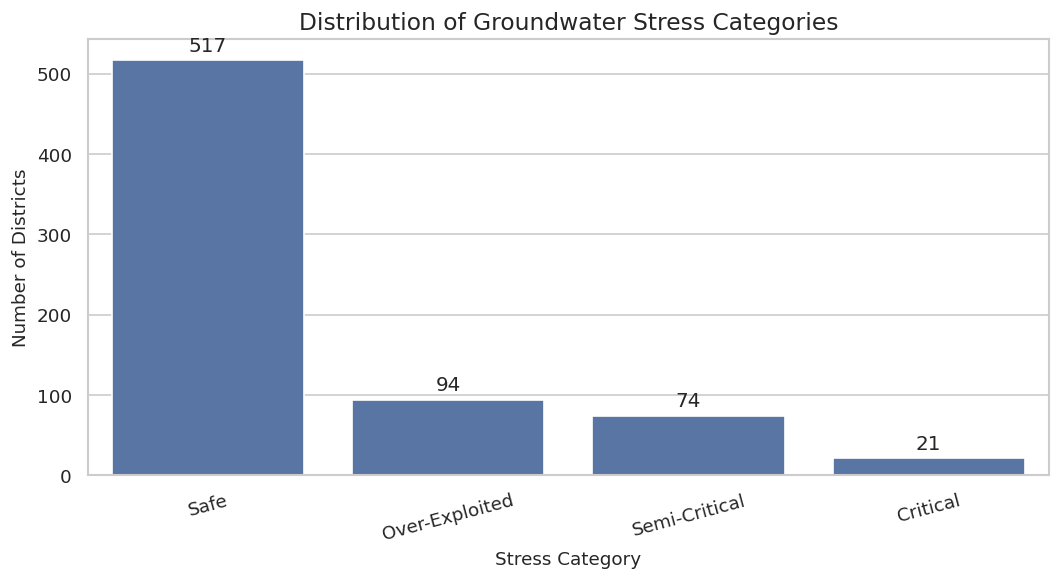

In [12]:
# BAR CHART: GROUNDWATER STRESS DISTRIBUTION

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=stress_summary,
    x="Stress_Category",
    y="District_Count"
)

plt.title("Distribution of Groundwater Stress Categories")
plt.xlabel("Stress Category")
plt.ylabel("Number of Districts")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

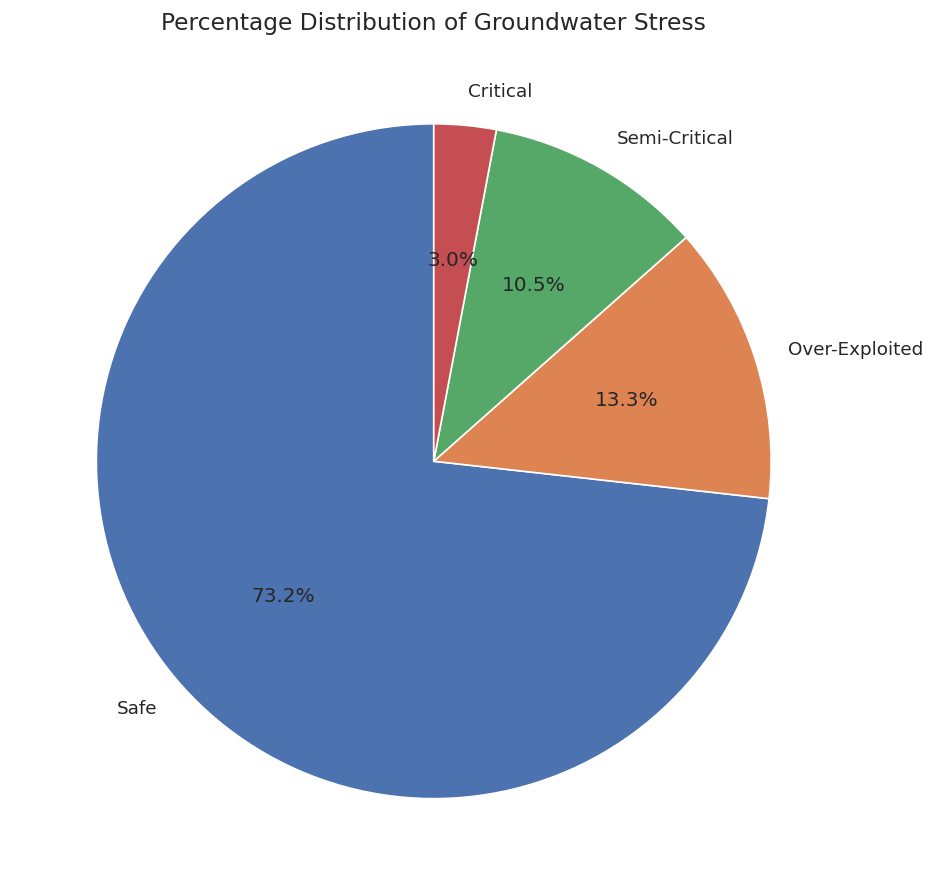

In [13]:
# PIE CHART: GROUNDWATER STRESS DISTRIBUTION

plt.figure(figsize=(8, 8))

plt.pie(
    stress_summary["District_Count"],
    labels=stress_summary["Stress_Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Groundwater Stress")
plt.tight_layout()
plt.show()

State-wise Groundwater Analysis

In [14]:
# STATE-WISE GROUNDWATER ANALYSIS

state_summary = (
    df.groupby("State")
    .agg(
        Total_Extractable_Resource=("Extractable_Resource", "sum"),
        Total_Extraction=("Total_Annual_Extraction", "sum"),
        Average_District_Stage=("Extraction_Stage_Percent", "mean"),
        District_Count=("District", "count")
    )
    .reset_index()
)

# Calculate weighted extraction stage
state_summary["Weighted_Extraction_Stage"] = (
    state_summary["Total_Extraction"] /
    state_summary["Total_Extractable_Resource"]
) * 100

state_summary = state_summary.sort_values(
    by="Weighted_Extraction_Stage",
    ascending=False
)

print("STATE-WISE GROUNDWATER EXTRACTION ANALYSIS")

display(state_summary.round(2))

STATE-WISE GROUNDWATER EXTRACTION ANALYSIS


,State,Total_Extractable_Resource,Total_Extraction,Average_District_Stage,District_Count,Weighted_Extraction_Stage
27,Punjab,1679943.44,2626761.47,161.15,23,156.36
28,Rajasthan,1162168.28,1709620.10,145.83,33,147.11
11,Haryana,930112.81,1271939.84,133.99,22,136.75
8,Delhi,34557.15,31828.23,92.17,12,92.10
26,Puducherry,17439.62,13251.37,62.44,2,75.98
30,Tamil Nadu,2045755.19,1503691.17,77.35,37,73.50
33,Uttar Pradesh,6697390.82,4688501.16,72.64,75,70.00
5,Chandigarh,4786.58,3206.89,67.00,1,67.00
15,Karnataka,1741410.74,1157913.85,75.42,31,66.49
19,Madhya Pradesh,3414882.36,2025793.91,58.67,55,59.32


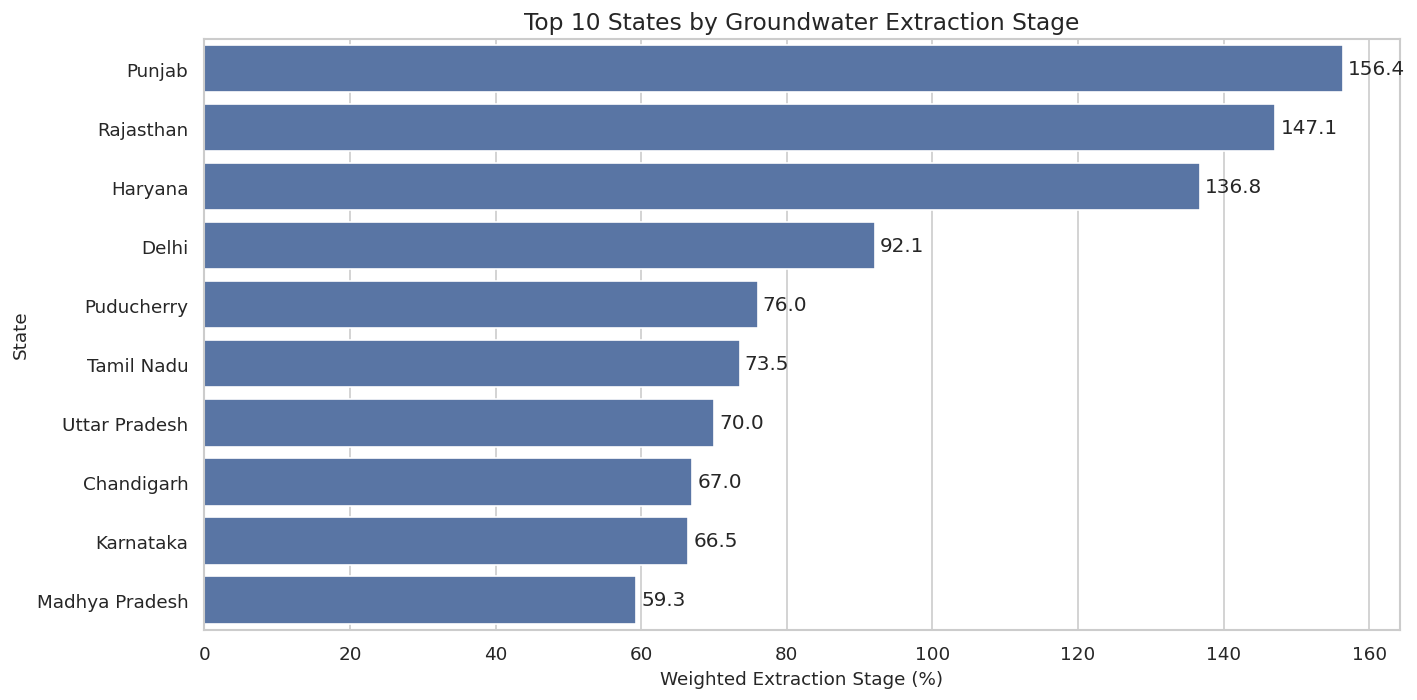

In [15]:
# TOP 10 STATES BY WEIGHTED EXTRACTION STAGE

top_states = state_summary.head(10)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_states,
    x="Weighted_Extraction_Stage",
    y="State"
)

plt.title("Top 10 States by Groundwater Extraction Stage")
plt.xlabel("Weighted Extraction Stage (%)")
plt.ylabel("State")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

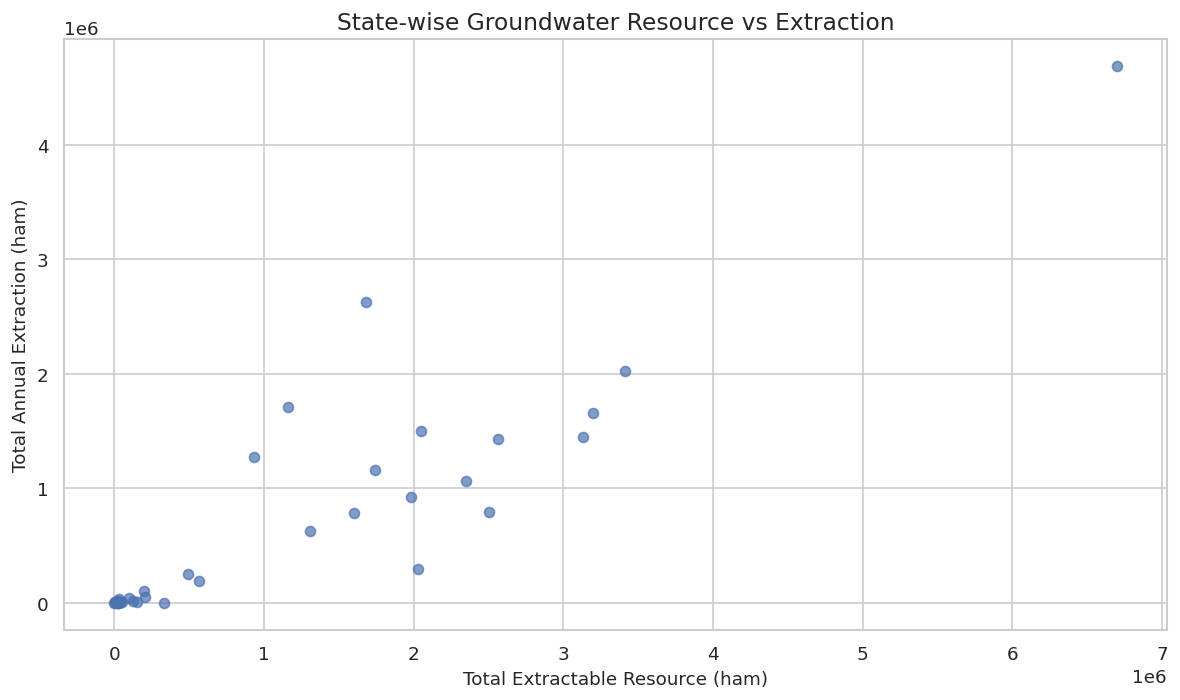

In [16]:
# STATE-WISE RESOURCE VS EXTRACTION

plt.figure(figsize=(10, 6))

plt.scatter(
    state_summary["Total_Extractable_Resource"],
    state_summary["Total_Extraction"],
    alpha=0.7
)

plt.title("State-wise Groundwater Resource vs Extraction")
plt.xlabel("Total Extractable Resource (ham)")
plt.ylabel("Total Annual Extraction (ham)")

plt.tight_layout()
plt.show()

Sector-wise Groundwater Extraction Analysis

In [17]:
# SECTOR-WISE GROUNDWATER EXTRACTION

sector_totals = {
    "Irrigation": df["Irrigation_Extraction"].sum(),
    "Industrial": df["Industrial_Extraction"].sum(),
    "Domestic": df["Domestic_Extraction"].sum()
}

sector_summary = pd.DataFrame(
    list(sector_totals.items()),
    columns=["Sector", "Total_Extraction"]
)

total_extraction = sector_summary["Total_Extraction"].sum()

sector_summary["Percentage"] = (
    sector_summary["Total_Extraction"] /
    total_extraction * 100
)

sector_summary["Percentage"] = sector_summary["Percentage"].round(2)

print("SECTOR-WISE GROUNDWATER EXTRACTION SUMMARY")

display(sector_summary.round(2))

SECTOR-WISE GROUNDWATER EXTRACTION SUMMARY


,Sector,Total_Extraction,Percentage
0,Irrigation,21509803.08,87.01
1,Industrial,422699.58,1.71
2,Domestic,2789039.87,11.28


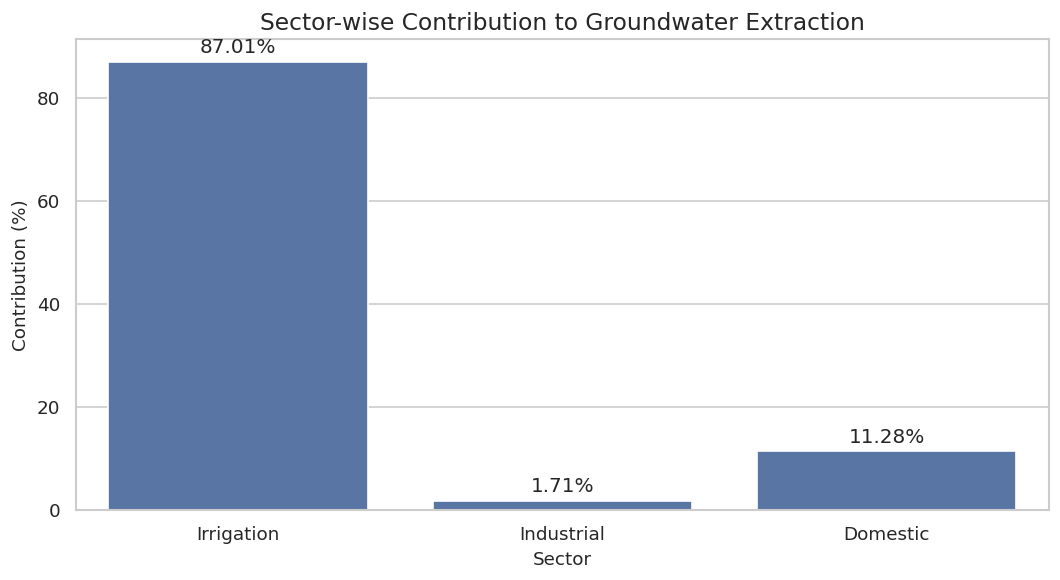

In [18]:
# BAR CHART: SECTOR-WISE EXTRACTION

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=sector_summary,
    x="Sector",
    y="Percentage"
)

plt.title("Sector-wise Contribution to Groundwater Extraction")
plt.xlabel("Sector")
plt.ylabel("Contribution (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

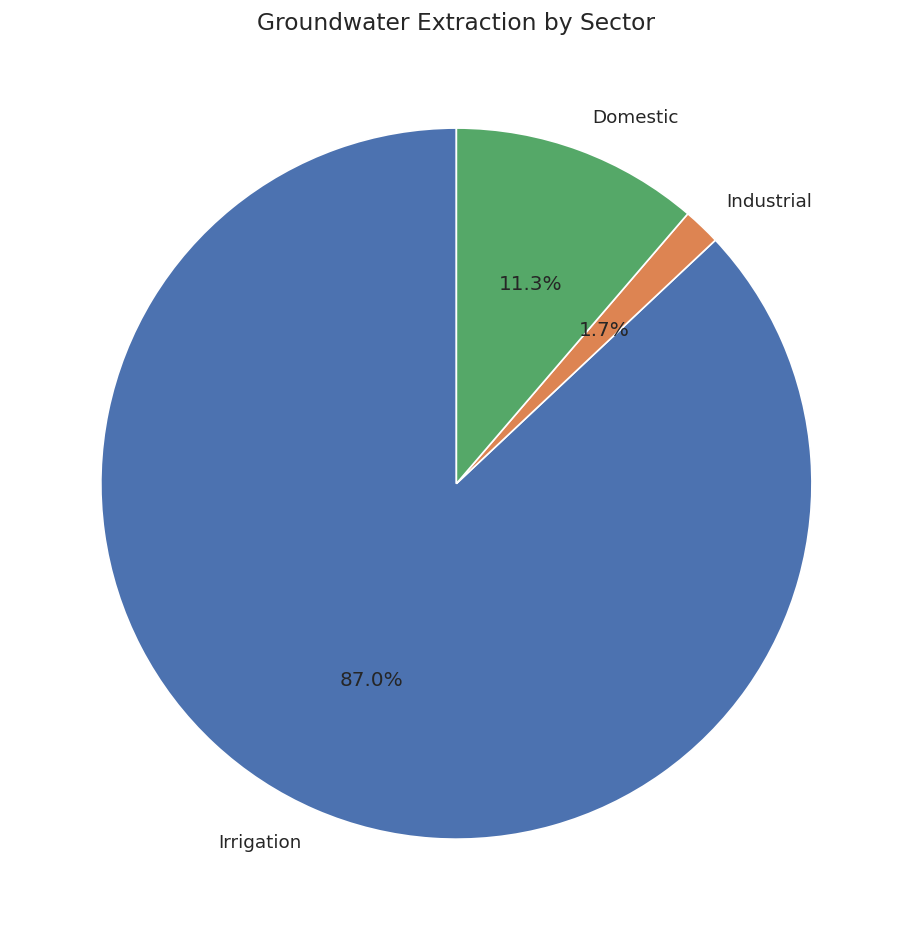

In [19]:
# PIE CHART: SECTOR CONTRIBUTION

plt.figure(figsize=(8, 8))

plt.pie(
    sector_summary["Total_Extraction"],
    labels=sector_summary["Sector"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Groundwater Extraction by Sector")
plt.tight_layout()
plt.show()

Statistical Analysis

In [20]:
# STATISTICAL CORRELATION ANALYSIS

irrigation_corr = df["Irrigation_Share_Percent"]
extraction_stage = df["Extraction_Stage_Percent"]

# Pearson correlation
pearson_r, pearson_p = pearsonr(
    irrigation_corr,
    extraction_stage
)

# Spearman correlation
spearman_r, spearman_p = spearmanr(
    irrigation_corr,
    extraction_stage
)

print("CORRELATION ANALYSIS")
print("=" * 45)

print(f"Pearson Correlation: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.6f}")

print(f"\nSpearman Correlation: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.6f}")

CORRELATION ANALYSIS
Pearson Correlation: 0.3931
Pearson p-value: 0.000000

Spearman Correlation: 0.5452
Spearman p-value: 0.000000


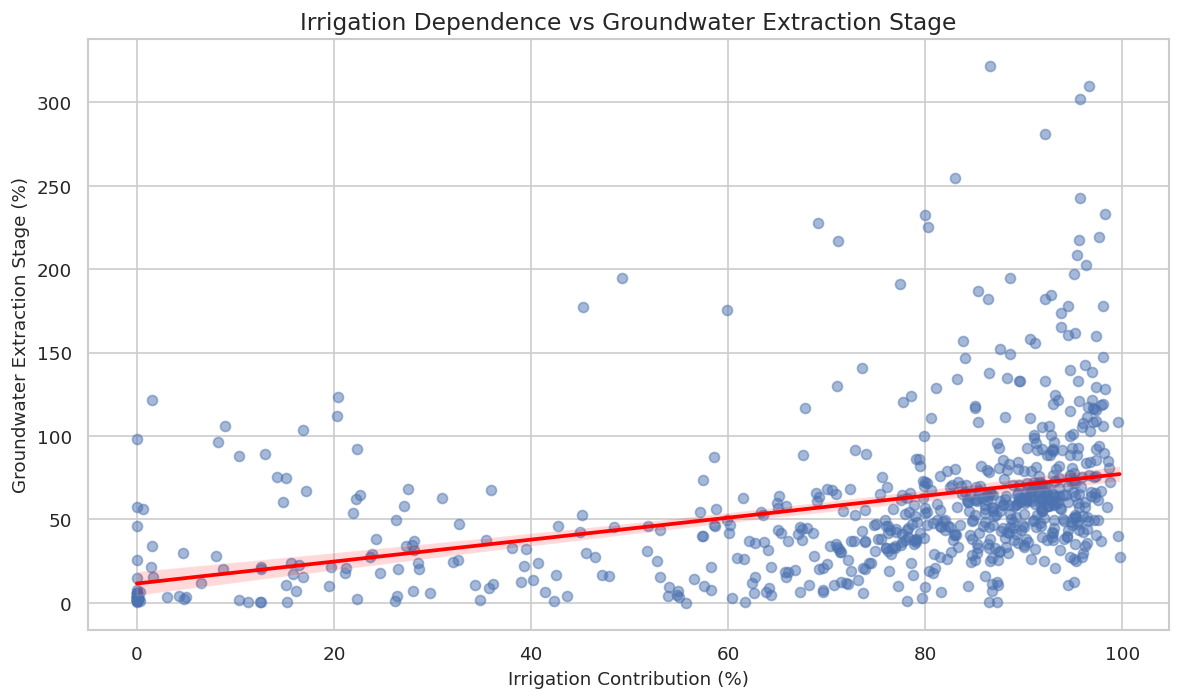

In [21]:
# SCATTER PLOT WITH REGRESSION LINE

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Irrigation_Share_Percent",
    y="Extraction_Stage_Percent",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Irrigation Dependence vs Groundwater Extraction Stage")
plt.xlabel("Irrigation Contribution (%)")
plt.ylabel("Groundwater Extraction Stage (%)")

plt.tight_layout()
plt.show()

In [22]:
# INTERPRETATION OF CORRELATION

if pearson_p < 0.05:
    print("Pearson correlation is statistically significant.")
else:
    print("Pearson correlation is not statistically significant.")

if spearman_p < 0.05:
    print("Spearman correlation is statistically significant.")
else:
    print("Spearman correlation is not statistically significant.")

print("\nNote: Correlation does not imply causation.")

Pearson correlation is statistically significant.
Spearman correlation is statistically significant.

Note: Correlation does not imply causation.



Rajasthan District-Level Analysis


In [23]:
# RAJASTHAN GROUNDWATER ANALYSIS

rajasthan_df = df[df["State"] == "Rajasthan"].copy()

rajasthan_summary = rajasthan_df[
    ["District", "Extractable_Resource",
     "Total_Annual_Extraction", "Extraction_Stage_Percent",
     "Stress_Category"]
].sort_values(
    by="Extraction_Stage_Percent",
    ascending=False
)

print("RAJASTHAN GROUNDWATER ANALYSIS")
print("Number of districts:", len(rajasthan_df))
print("Average extraction stage:",
      round(rajasthan_df["Extraction_Stage_Percent"].mean(), 2), "%")

display(rajasthan_summary.round(2))

RAJASTHAN GROUNDWATER ANALYSIS
Number of districts: 33
Average extraction stage: 145.83 %


,District,Extractable_Resource,Total_Annual_Extraction,Extraction_Stage_Percent,Stress_Category
462,Jaisalmer,9614.27,30942.89,321.84,Over-Exploited
466,Jodhpur,38078.50,97087.88,254.97,Over-Exploited
456,Dausa,25184.08,58589.26,232.64,Over-Exploited
465,Jhunjhunu,22436.15,51052.73,227.55,Over-Exploited
461,Jaipur,71377.76,154900.23,217.01,Over-Exploited
474,Sikar,34927.43,66832.10,191.35,Over-Exploited
469,Nagaur,58659.20,109830.72,187.24,Over-Exploited
446,Alwar,70488.78,128390.72,182.14,Over-Exploited
463,Jalor,44656.19,79551.91,178.14,Over-Exploited
454,Chittaurgarh,31318.37,50693.12,161.86,Over-Exploited


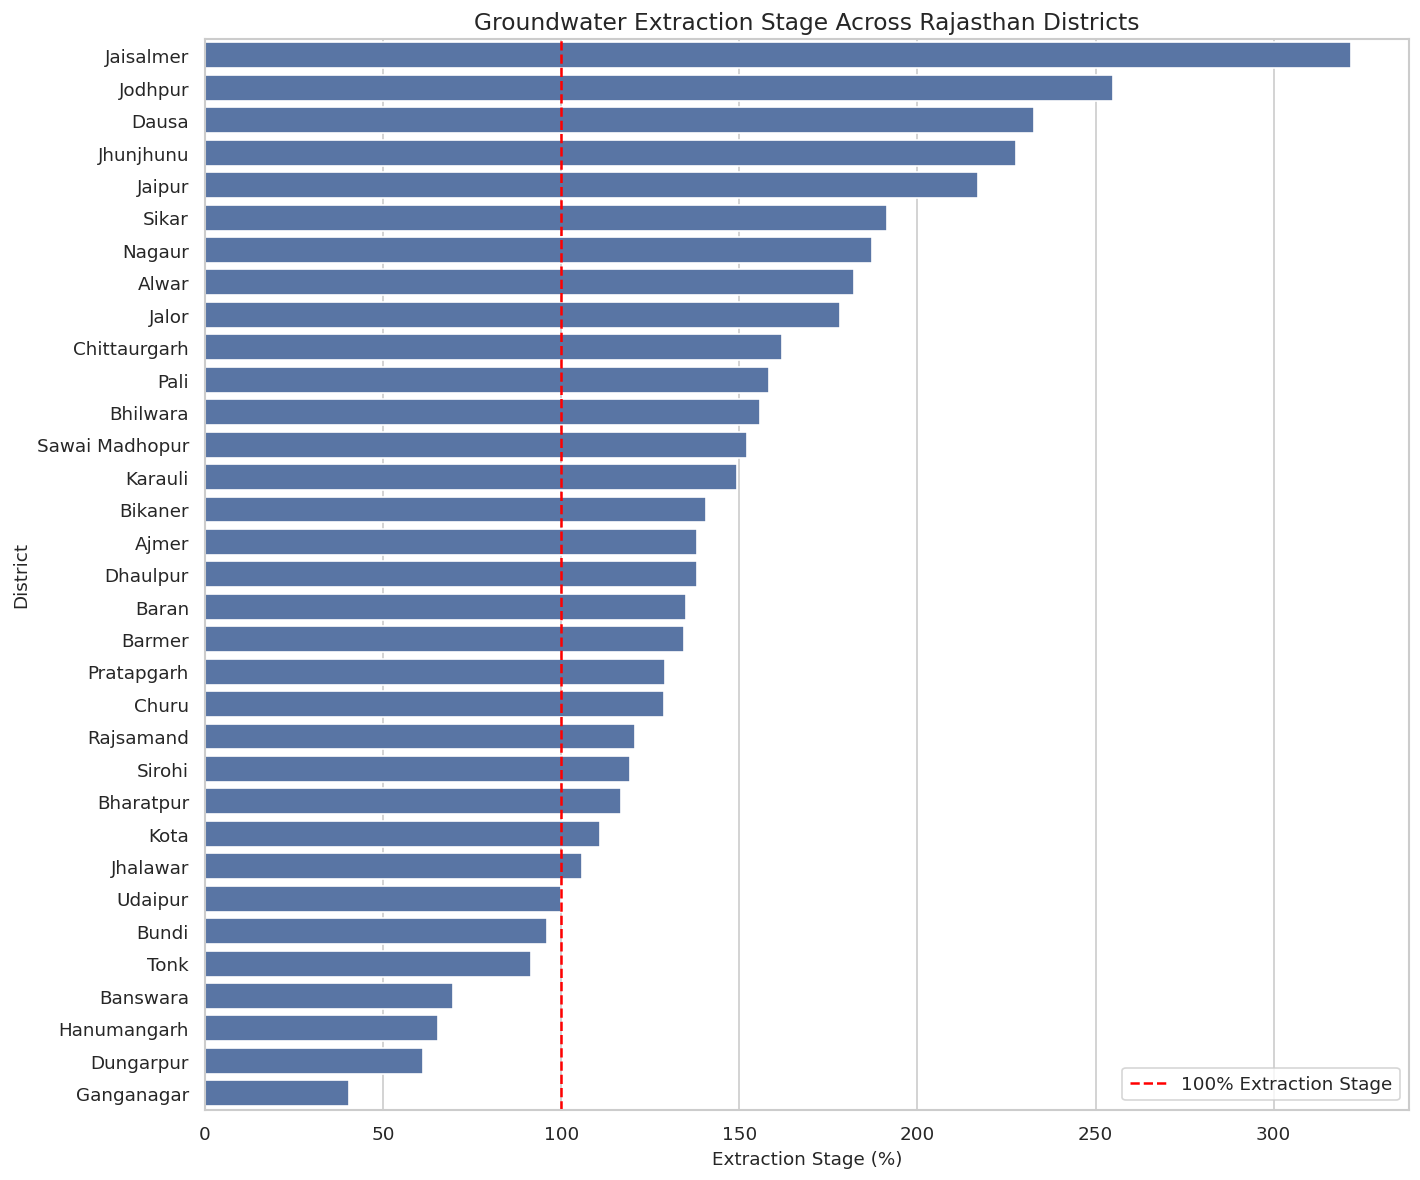

In [24]:
# BAR CHART: RAJASTHAN DISTRICT EXTRACTION STAGE

plt.figure(figsize=(12, 10))

sns.barplot(
    data=rajasthan_summary,
    x="Extraction_Stage_Percent",
    y="District"
)

plt.axvline(
    x=100,
    color="red",
    linestyle="--",
    label="100% Extraction Stage"
)

plt.title("Groundwater Extraction Stage Across Rajasthan Districts")
plt.xlabel("Extraction Stage (%)")
plt.ylabel("District")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
# DISTRICTS EXCEEDING 100% EXTRACTION STAGE

above_100 = (
    rajasthan_df["Extraction_Stage_Percent"] > 100
).sum()

below_100 = (
    rajasthan_df["Extraction_Stage_Percent"] <= 100
).sum()

print("Rajasthan District Analysis")
print("---------------------------")
print("Above 100%:", above_100)
print("At or below 100%:", below_100)
print("Total districts:", len(rajasthan_df))

Rajasthan District Analysis
---------------------------
Above 100%: 27
At or below 100%: 6
Total districts: 33


Key Findings

1. The average groundwater extraction stage across the 706 analysed districts is 59.30%.
2. A total of 94 districts are classified as Over-Exploited under the project's analytical thresholds.
3. Punjab, Rajasthan and Haryana have the highest weighted state-level extraction stages.
4. Irrigation accounts for 87.01% of total groundwater extraction.
5. Irrigation contribution has a moderate positive association with groundwater extraction stage.
6. Rajasthan has an average extraction stage of 145.83%, with 27 districts exceeding 100%.


Conclusion

The analysis highlights substantial regional differences in groundwater extraction across India. Although most analysed districts fall within the Safe category under the project's threshold-based classification, several districts show high extraction levels.

Agriculture is the dominant contributor to groundwater extraction, indicating the importance of efficient irrigation practices and sustainable water management.

The findings can help identify regions requiring further investigation and support data-driven groundwater conservation planning.


Limitations

- The study uses secondary data published by CGWB.
- The analysis is based on district-level aggregated data.
- Threshold-based district categories are analytical indicators and should not be confused with official CGWB assessment-unit classifications.
- Correlation indicates association, not causation.